In [1]:
import random
import time
import warnings
from pathlib import Path
%pip install ucimlrepo
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, f1_score, matthews_corrcoef,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

SEED = 42                      # fixed random seed used for the split and every model
random.seed(SEED)
np.random.seed(SEED)

# project root = folder that holds data/, results/, test_data.csv (works from root or from model/)
ROOT = Path.cwd().parent if Path.cwd().name == "model" else Path.cwd()
DATA_PATH = ROOT / "data" / "diabetic_data.csv"
RESULTS_DIR = ROOT / "results"
SAVED_DIR = ROOT / "model" / "saved"
RESULTS_DIR.mkdir(exist_ok=True)
SAVED_DIR.mkdir(parents=True, exist_ok=True)
print("Project root :", ROOT)
print("Dataset file :", DATA_PATH, "| exists:", DATA_PATH.exists())

Project root : /content
Dataset file : /content/data/diabetic_data.csv | exists: False


In [2]:
if DATA_PATH.exists():                      # 1) local copy of diabetic_data.csv
    df_raw = pd.read_csv(DATA_PATH, na_values=["?"], skipinitialspace=True)
else:                                       # 2) no file: download straight from UCI (dataset id 296)
    # needs internet access and:  pip install ucimlrepo
    from ucimlrepo import fetch_ucirepo
    uci = fetch_ucirepo(id=296)
    df_raw = pd.concat([uci.data.features, uci.data.targets], axis=1)
    DATA_PATH.parent.mkdir(exist_ok=True)
    df_raw.to_csv(DATA_PATH, index=False)   # keep a local copy so later runs do not need the internet
    print("Downloaded from UCI and saved to", DATA_PATH)
df_raw.columns = [c.strip() for c in df_raw.columns]
print("Raw shape (rows, columns):", df_raw.shape)
display(df_raw.head())

Downloaded from UCI and saved to /content/data/diabetic_data.csv
Raw shape (rows, columns): (101766, 48)


,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,...,No,No,No,No,No,No,No,No,No,NO
1,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,...,No,No,No,No,No,No,No,No,Yes,NO
3,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [3]:
TARGET = "readmitted"
ID_COLS = ["encounter_id", "patient_nbr"]        # identifiers: carry no medical meaning, would only cause memorisation
HIGH_MISSING = ["weight"]                        # almost entirely missing, cannot be imputed reliably
CODED_CATEGORICAL = ["admission_type_id", "discharge_disposition_id", "admission_source_id"]  # integer codes, not quantities

print("Share of missing values in 'weight': {:.1%}".format(df_raw["weight"].isna().mean()))
df = df_raw.drop(columns=[c for c in ID_COLS + HIGH_MISSING if c in df_raw.columns]).copy()

# integer codes that really are categories must not be scaled as numbers
for c in CODED_CATEGORICAL:
    if c in df.columns:
        df[c] = df[c].astype("string").astype(object).where(df[c].notna(), np.nan)

# gender has a handful of 'Unknown/Invalid' rows: treat them as missing
if "gender" in df.columns:
    df["gender"] = df["gender"].replace("Unknown/Invalid", np.nan)

n_features = df.shape[1] - 1
print(f"Instances: {len(df):,} | Input features used: {n_features}")
assert len(df) >= 1000, "dataset must have at least 1,000 instances"
assert n_features >= 12, "dataset must have at least 12 features"
print("Minimum requirements satisfied (>= 12 features, >= 1,000 instances).")

Share of missing values in 'weight': 96.9%
Instances: 101,766 | Input features used: 46
Minimum requirements satisfied (>= 12 features, >= 1,000 instances).


In [4]:
X_all = df.drop(columns=[TARGET])
num_cols = X_all.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in X_all.columns if c not in num_cols]
print(f"Numerical features ({len(num_cols)}):\n{num_cols}\n")
print(f"Categorical features ({len(cat_cols)}):\n{cat_cols}")

Numerical features (8):
['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']

Categorical features (38):
['race', 'gender', 'age', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed']


,count,percent
readmitted,,
NO,54864,53.91
>30,35545,34.93
<30,11357,11.16


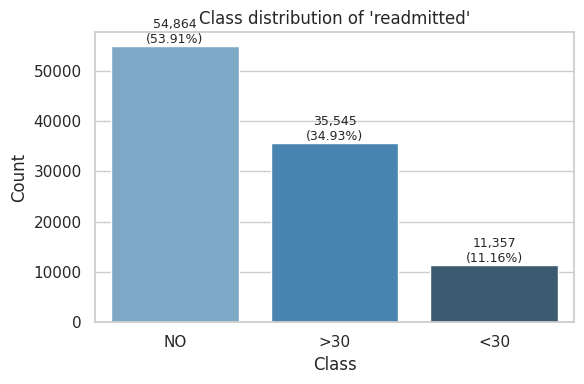

**Class distribution finding:** the largest class (`NO`) holds 53.91% of the rows and the smallest class (`<30`) only 11.16%, an imbalance ratio of 4.8 : 1. A model that always predicts `NO` would already score 53.9% accuracy, so accuracy alone cannot be trusted here; AUC, MCC and the recall of the minority class `<30` are examined as well.

In [5]:
class_counts = df[TARGET].value_counts()
class_pct = (class_counts / len(df) * 100).round(2)
dist = pd.DataFrame({"count": class_counts, "percent": class_pct})
display(dist)

majority_baseline = class_counts.max() / len(df)
imbalance_ratio = class_counts.max() / class_counts.min()
minority_label = class_counts.idxmin()

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=class_counts.index.astype(str), y=class_counts.values, ax=ax, palette="Blues_d")
for i, v in enumerate(class_counts.values):
    ax.text(i, v, f"{v:,}\n({class_pct.iloc[i]}%)", ha="center", va="bottom", fontsize=9)
ax.set_title("Class distribution of 'readmitted'")
ax.set_xlabel("Class"); ax.set_ylabel("Count")
fig.tight_layout(); fig.savefig(RESULTS_DIR / "class_distribution.png", dpi=150); plt.show()

display(Markdown(
    f"**Class distribution finding:** the largest class (`{class_counts.idxmax()}`) holds {class_pct.max()}% of the rows and the "
    f"smallest class (`{minority_label}`) only {class_pct.min()}%, an imbalance ratio of {imbalance_ratio:.1f} : 1. "
    f"A model that always predicts `{class_counts.idxmax()}` would already score {majority_baseline:.1%} accuracy, so accuracy alone "
    f"cannot be trusted here; AUC, MCC and the recall of the minority class `{minority_label}` are examined as well."
))

In [6]:
miss = df.isna().sum()
miss_tbl = pd.DataFrame({"missing": miss, "percent": (miss / len(df) * 100).round(2)})
miss_tbl = miss_tbl[miss_tbl["missing"] > 0].sort_values("missing", ascending=False)
display(miss_tbl if len(miss_tbl) else Markdown("No missing values found."))

,missing,percent
max_glu_serum,96420,94.75
A1Cresult,84748,83.28
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02
gender,3,0.00


In [7]:
dup_raw = df_raw.duplicated().sum()
dup_features = df.duplicated().sum()
print(f"Duplicate rows in the raw file (including ID columns): {dup_raw}")
print(f"Duplicate rows after removing ID columns / weight   : {dup_features}")

# rows with a missing target cannot be used for supervised learning
before = len(df)
df = df.dropna(subset=[TARGET]).drop_duplicates().reset_index(drop=True)
print(f"Rows removed (missing target + duplicates): {before - len(df)} | rows remaining: {len(df):,}")

Duplicate rows in the raw file (including ID columns): 0
Duplicate rows after removing ID columns / weight   : 0
Rows removed (missing target + duplicates): 0 | rows remaining: 101,766


In [8]:
label_enc = LabelEncoder()
y = label_enc.fit_transform(df[TARGET])
class_names = list(label_enc.classes_)
print("Target encoding:", dict(enumerate(class_names)))

X = df.drop(columns=[TARGET])
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED     # stratify keeps the class distribution
)
print(f"Train: {X_train.shape} | Test: {X_test.shape}")
chk = pd.DataFrame({
    "full data %": pd.Series(y).value_counts(normalize=True).sort_index() * 100,
    "train %": pd.Series(y_train).value_counts(normalize=True).sort_index() * 100,
    "test %": pd.Series(y_test).value_counts(normalize=True).sort_index() * 100,
}).round(2)
chk.index = class_names
display(chk)

# save the raw (un-preprocessed) test set required in the GitHub repo
test_out = X_test.copy()
test_out[TARGET] = label_enc.inverse_transform(y_test)
test_out.to_csv(ROOT / "test_data.csv", index=False)
print("Saved:", ROOT / "test_data.csv")

Target encoding: {0: '<30', 1: '>30', 2: 'NO'}
Train: (81412, 46) | Test: (20354, 46)


,full data %,train %,test %
<30,11.16,11.16,11.16
>30,34.93,34.93,34.93
NO,53.91,53.91,53.91


Saved: /content/test_data.csv


In [9]:
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in X_train.columns if c not in num_cols]


def make_preprocessor():
    """Numeric: median impute + standardise. Categorical: 'Missing' level + one-hot.
    Categories used by fewer than 1% of rows are pooled into one 'infrequent' group, so the
    diagnosis columns (hundreds of ICD-9 codes) do not create thousands of columns."""
    numeric = Pipeline([("impute", SimpleImputer(strategy="median")),
                        ("scale", StandardScaler())])
    categorical = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
                            ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                                     min_frequency=0.01, sparse_output=False))])
    return ColumnTransformer([("num", numeric, num_cols), ("cat", categorical, cat_cols)])


print(f"{len(num_cols)} numerical and {len(cat_cols)} categorical columns go into the preprocessor.")

8 numerical and 38 categorical columns go into the preprocessor.


In [10]:
from sklearn.base import clone
from sklearn.metrics import make_scorer
from sklearn.model_selection import GridSearchCV, StratifiedKFold
import json

# --- Hyper-parameter tuning: cross-validation on the TRAINING data only (the test set is never touched) ---
TUNE_ROWS = min(20000, len(X_train))              # random subsample of the training rows keeps tuning fast
tune_idx = np.random.RandomState(SEED).choice(len(X_train), size=TUNE_ROWS, replace=False)
X_tune, y_tune = X_train.iloc[tune_idx], y_train[tune_idx]
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
mcc_scorer = make_scorer(matthews_corrcoef)       # MCC copes well with an imbalanced multi-class target

search_space = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, random_state=SEED),
                            {"clf__C": [0.01, 0.1, 1.0]}),
    "Decision Tree": (DecisionTreeClassifier(criterion="gini", random_state=SEED),
                      {"clf__max_depth": [4, 6, 8, 12], "clf__min_samples_leaf": [5, 20, 50]}),
    "kNN": (KNeighborsClassifier(weights="uniform", metric="minkowski", p=2, n_jobs=-1),
            {"clf__n_neighbors": [15, 31, 61, 101]}),
    "Naive Bayes": (GaussianNB(),
                    {"clf__var_smoothing": [1e-9, 1e-4, 1e-2, 1e-1, 5e-1]}),
    "Random Forest (Ensemble)": (RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED),
                                 {"clf__max_depth": [8, 12, None], "clf__min_samples_leaf": [2, 10, 30]}),
}

models, best_params = {}, {}
for name, (est, grid) in search_space.items():
    t0 = time.time()
    search = GridSearchCV(Pipeline([("preprocess", make_preprocessor()), ("clf", est)]), grid,
                          scoring=mcc_scorer, cv=cv, n_jobs=1, refit=False)
    search.fit(X_tune, y_tune)                    # preprocessing is re-fitted inside every CV fold
    best = {k.replace("clf__", ""): v for k, v in search.best_params_.items()}
    models[name] = clone(est).set_params(**best)
    best_params[name] = best
    print(f"{name:<26} best settings {best} | CV MCC {search.best_score_:.4f} | {time.time() - t0:.0f}s")
(RESULTS_DIR / "best_params.json").write_text(json.dumps(best_params, indent=2, default=str), encoding="utf-8")
METRICS = ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]
n_classes = len(class_names)


def evaluate(pipe, X_, y_):
    pred = pipe.predict(X_)
    proba = pipe.predict_proba(X_)
    avg = "binary" if n_classes == 2 else "weighted"
    auc = roc_auc_score(y_, proba[:, 1]) if n_classes == 2 else roc_auc_score(y_, proba, multi_class="ovr", average="macro")
    scores = {
        "Accuracy": accuracy_score(y_, pred),
        "AUC": auc,
        "Precision": precision_score(y_, pred, average=avg, zero_division=0),
        "Recall": recall_score(y_, pred, average=avg, zero_division=0),
        "F1": f1_score(y_, pred, average=avg, zero_division=0),
        "MCC": matthews_corrcoef(y_, pred),
    }
    return scores, pred


fitted, rows, preds, train_acc, fit_seconds = {}, {}, {}, {}, {}
for name, clf in models.items():
    pipe = Pipeline([("preprocess", make_preprocessor()), ("clf", clf)])
    t0 = time.time()
    pipe.fit(X_train, y_train)                       # preprocessing is fitted on X_train only
    fit_seconds[name] = time.time() - t0
    rows[name], preds[name] = evaluate(pipe, X_test, y_test)
    train_acc[name] = pipe.score(X_train, y_train)
    fitted[name] = pipe
    joblib.dump(pipe, SAVED_DIR / (name.split(" (")[0].lower().replace(" ", "_") + ".joblib"))
    print(f"{name:<26} trained in {fit_seconds[name]:6.1f}s | test accuracy {rows[name]['Accuracy']:.4f}")

n_encoded = fitted["Logistic Regression"].named_steps["preprocess"].transform(X_test.head(2)).shape[1]
print(f"\nFeatures after encoding: {n_encoded}")

Logistic Regression        best settings {'C': 0.1} | CV MCC 0.1997 | 44s
Decision Tree              best settings {'max_depth': 4, 'min_samples_leaf': 5} | CV MCC 0.1836 | 21s
kNN                        best settings {'n_neighbors': 101} | CV MCC 0.1599 | 21s
Naive Bayes                best settings {'var_smoothing': 0.1} | CV MCC 0.1655 | 8s
Random Forest (Ensemble)   best settings {'max_depth': None, 'min_samples_leaf': 2} | CV MCC 0.1916 | 68s
Logistic Regression        trained in   16.2s | test accuracy 0.5831
Decision Tree              trained in    2.9s | test accuracy 0.5748
kNN                        trained in    2.6s | test accuracy 0.5748
Naive Bayes                trained in    2.4s | test accuracy 0.5607
Random Forest (Ensemble)   trained in   25.9s | test accuracy 0.5911

Features after encoding: 205


In [11]:
results = pd.DataFrame(rows).T[METRICS]
results.index.name = "ML Model Name"
results.round(4).to_csv(RESULTS_DIR / "metrics_comparison.csv")
display(results.round(4))


def to_markdown_table(res):
    head = "| **ML Model Name** | " + " | ".join(f"**{m}**" for m in METRICS) + " |"
    sep = "| --- " * (len(METRICS) + 1) + "|"
    body = [f"| **{n}** | " + " | ".join(f"{r[m]:.4f}" for m in METRICS) + " |" for n, r in res.iterrows()]
    return "\n".join([head, sep] + body)


table_md = to_markdown_table(results)
(RESULTS_DIR / "metrics_table.md").write_text(table_md, encoding="utf-8")
print("Markdown version of the table (paste into README.md):\n")
print(table_md)

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.5831,0.6727,0.5453,0.5831,0.5287,0.1973
Decision Tree,0.5748,0.6306,0.4947,0.5748,0.5212,0.1799
kNN,0.5748,0.6458,0.5461,0.5748,0.4996,0.1694
Naive Bayes,0.5607,0.6443,0.5205,0.5607,0.5066,0.1626
Random Forest (Ensemble),0.5911,0.6793,0.5842,0.5911,0.5375,0.2143


Markdown version of the table (paste into README.md):

| **ML Model Name** | **Accuracy** | **AUC** | **Precision** | **Recall** | **F1** | **MCC** |
| --- | --- | --- | --- | --- | --- | --- |
| **Logistic Regression** | 0.5831 | 0.6727 | 0.5453 | 0.5831 | 0.5287 | 0.1973 |
| **Decision Tree** | 0.5748 | 0.6306 | 0.4947 | 0.5748 | 0.5212 | 0.1799 |
| **kNN** | 0.5748 | 0.6458 | 0.5461 | 0.5748 | 0.4996 | 0.1694 |
| **Naive Bayes** | 0.5607 | 0.6443 | 0.5205 | 0.5607 | 0.5066 | 0.1626 |
| **Random Forest (Ensemble)** | 0.5911 | 0.6793 | 0.5842 | 0.5911 | 0.5375 | 0.2143 |


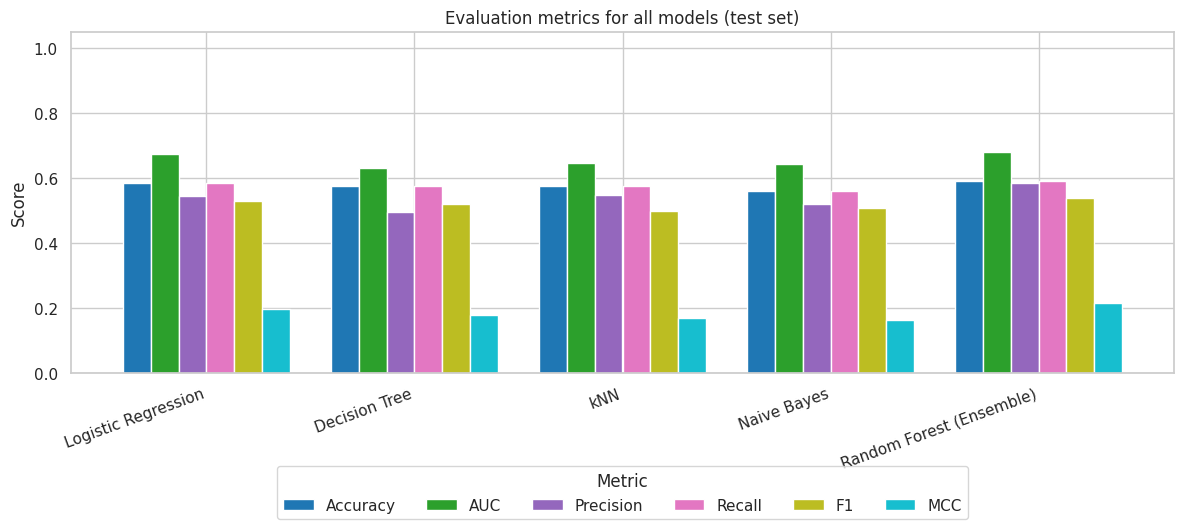

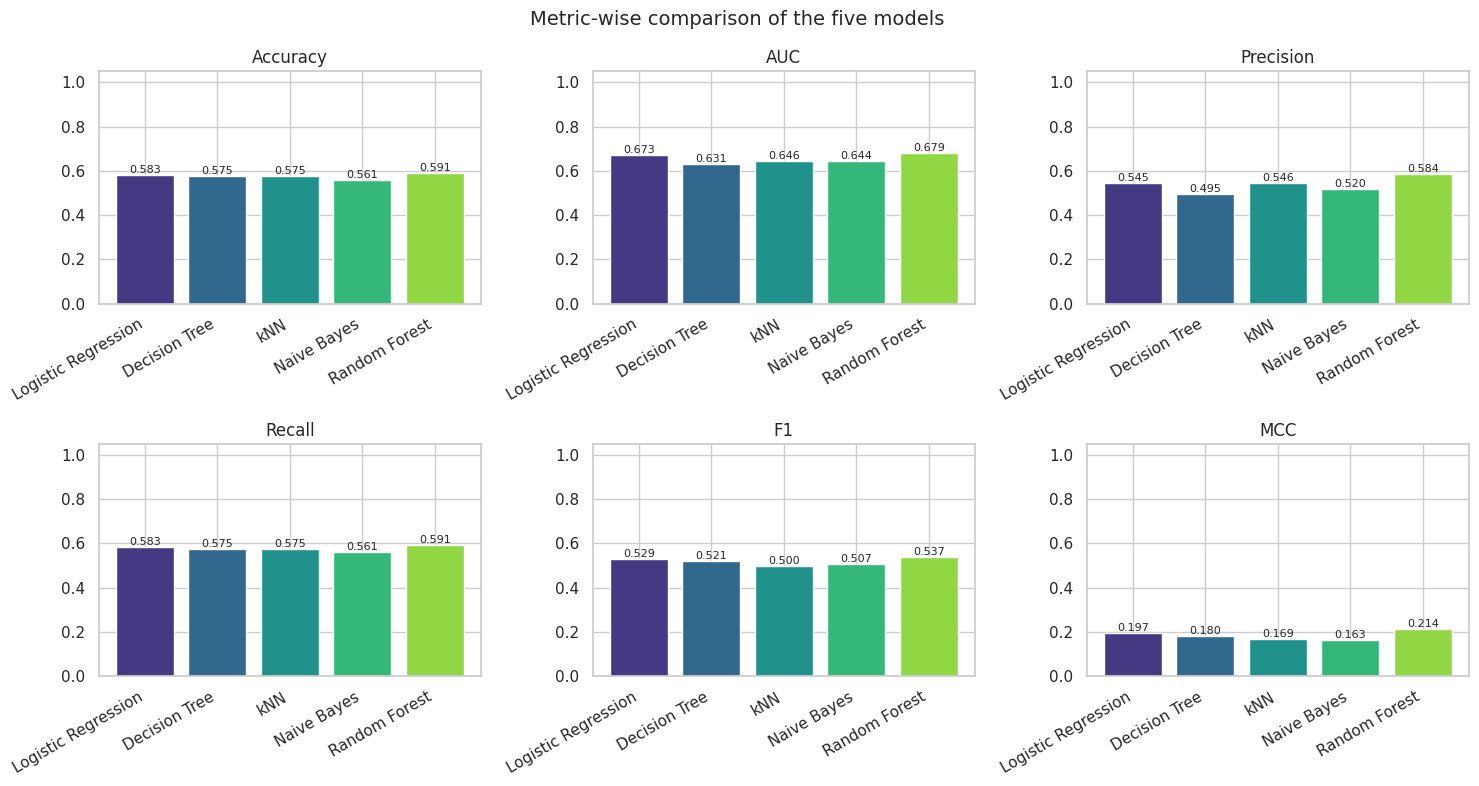

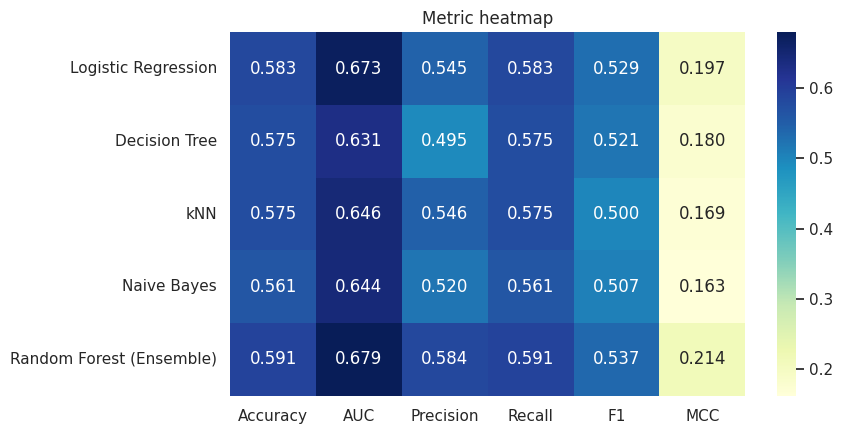

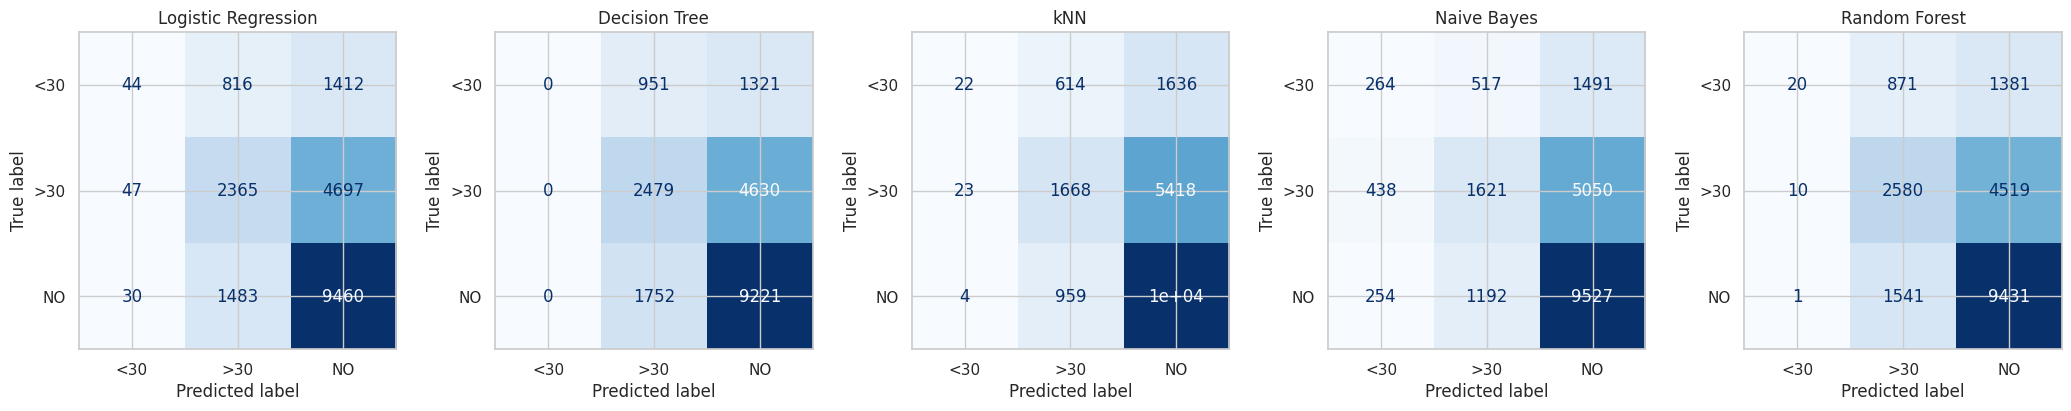

In [12]:
# 1) all six metrics for all models
ax = results[METRICS].plot(kind="bar", figsize=(12, 6), width=0.8, colormap="tab10")
ax.set_title("Evaluation metrics for all models (test set)")
ax.set_ylabel("Score"); ax.set_xlabel("")
ax.set_ylim(0, 1.05)
ax.legend(title="Metric", loc="lower center", ncol=6, bbox_to_anchor=(0.5, -0.45))
plt.xticks(rotation=20, ha="right"); plt.tight_layout()
plt.savefig(RESULTS_DIR / "metrics_bar_chart.png", dpi=150, bbox_inches="tight"); plt.show()

# 2) one panel per metric
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, metric in zip(axes.ravel(), METRICS):
    vals = results[metric]
    ax.bar(range(len(vals)), vals.values, color=sns.color_palette("viridis", len(vals)))
    ax.set_xticks(range(len(vals)))
    ax.set_xticklabels([n.replace(" (Ensemble)", "") for n in vals.index], rotation=30, ha="right")
    ax.set_title(metric); ax.set_ylim(0, 1.05)
    for i, v in enumerate(vals.values):
        ax.text(i, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8)
fig.suptitle("Metric-wise comparison of the five models", fontsize=14)
fig.tight_layout(); fig.savefig(RESULTS_DIR / "metrics_per_metric.png", dpi=150); plt.show()

# 3) heatmap
plt.figure(figsize=(9, 4.5))
sns.heatmap(results.astype(float), annot=True, fmt=".3f", cmap="YlGnBu")
plt.title("Metric heatmap"); plt.ylabel("")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "metrics_heatmap.png", dpi=150); plt.show()

# 4) confusion matrices
fig, axes = plt.subplots(1, len(preds), figsize=(4.2 * len(preds), 4))
for ax, (name, pred) in zip(axes, preds.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=class_names, ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name.replace(" (Ensemble)", ""))
fig.tight_layout(); fig.savefig(RESULTS_DIR / "confusion_matrices.png", dpi=150); plt.show()

In [13]:
gap_tbl = pd.DataFrame({"Train accuracy": pd.Series(train_acc), "Test accuracy": results["Accuracy"]})
gap_tbl["Gap (train - test)"] = gap_tbl["Train accuracy"] - gap_tbl["Test accuracy"]
gap_tbl["Training time (s)"] = pd.Series(fit_seconds)
display(gap_tbl.round(4))

minority_idx = class_names.index(minority_label)
per_class = pd.DataFrame(
    {n: recall_score(y_test, p, average=None, labels=range(n_classes), zero_division=0) for n, p in preds.items()},
    index=[f"Recall for '{c}'" for c in class_names],
).T
display(per_class.round(4))
gap_tbl.round(4).to_csv(RESULTS_DIR / "train_vs_test_accuracy.csv")
per_class.round(4).to_csv(RESULTS_DIR / "per_class_recall.csv")

,Train accuracy,Test accuracy,Gap (train - test),Training time (s)
Logistic Regression,0.5858,0.5831,0.0027,16.2423
Decision Tree,0.5735,0.5748,-0.0013,2.9017
kNN,0.5841,0.5748,0.0093,2.5866
Naive Bayes,0.5649,0.5607,0.0042,2.4371
Random Forest (Ensemble),0.9009,0.5911,0.3099,25.8677


,Recall for '<30',Recall for '>30',Recall for 'NO'
Logistic Regression,0.0194,0.3327,0.8621
Decision Tree,0.0000,0.3487,0.8403
kNN,0.0097,0.2346,0.9122
Naive Bayes,0.1162,0.2280,0.8682
Random Forest (Ensemble),0.0088,0.3629,0.8595


In [14]:
ranks = results.rank(ascending=False, method="min").astype(int)
rec_col = f"Recall for '{minority_label}'"


def ordinal(n):
    return {1: "first", 2: "second", 3: "third", 4: "fourth", 5: "fifth"}.get(n, f"{n}th")


traits = {
    "Logistic Regression": "As a linear model it is fast and stable, but it cannot capture complicated interactions between features.",
    "Decision Tree": "A single depth-limited tree is easy to interpret, but one tree on its own tends to be unstable.",
    "kNN": f"kNN compares patients by distance, and with {n_encoded} encoded features those distances become less meaningful.",
    "Naive Bayes": "It assumes the features are independent and bell-shaped, which does not suit one-hot and medication columns.",
    "Random Forest (Ensemble)": "It averages many different trees, which reduces variance and picks up non-linear patterns.",
}


def accuracy_sentence(acc):
    if acc < majority_baseline:
        return f"Its accuracy is below the {majority_baseline:.3f} I would get by always predicting '{class_counts.idxmax()}'."
    if acc - majority_baseline < 0.05:
        return f"Its accuracy is only slightly above the {majority_baseline:.3f} baseline of always predicting '{class_counts.idxmax()}'."
    return f"Its accuracy is clearly above the {majority_baseline:.3f} baseline of always predicting '{class_counts.idxmax()}'."


def fit_sentence(gap):
    if gap > 0.10:
        return f"Training accuracy is far above test accuracy (gap {gap:.3f}), so it overfits."
    if gap > 0.03:
        return f"There is a mild train-test gap of {gap:.3f}."
    return f"Training and test accuracy are close (gap {gap:.3f}), so it is not overfitting."


def minority_sentence(acc, rec):
    if acc < majority_baseline - 0.05 and rec > 0.5:
        return (f"Its recall for '{minority_label}' looks high ({rec:.3f}), but only because it gives that label to "
                f"almost every patient, so it is not a real strength.")
    return f"It finds {rec:.1%} of the '{minority_label}' cases."


obs_rows = []
for name in results.index:
    r = results.loc[name]
    gap = gap_tbl.loc[name, "Gap (train - test)"]
    rec = per_class.loc[name, rec_col]
    text = (
        f"{name} ranks {ordinal(ranks.loc[name, 'MCC'])} of {len(results)} on MCC ({r['MCC']:.3f}), with test accuracy "
        f"{r['Accuracy']:.3f}, AUC {r['AUC']:.3f} and F1 {r['F1']:.3f}. {accuracy_sentence(r['Accuracy'])} "
        f"{fit_sentence(gap)} {minority_sentence(r['Accuracy'], rec)} {traits[name]}"
    )
    obs_rows.append((name, text))

order = results["MCC"].sort_values(ascending=False)
winner, runner_up = order.index[0], order.index[1]
margin = order.iloc[0] - order.iloc[1]
n_won = sum(results[m].idxmax() == winner for m in METRICS)
w_gap = gap_tbl.loc[winner, "Gap (train - test)"]
w_rec = per_class.loc[winner, rec_col]

winner_text = (
    f"{winner} is the overall winner. It has the highest MCC ({results.loc[winner, 'MCC']:.3f}), the score I trust most for an "
    f"imbalanced multi-class target, and it is best on {n_won} of the {len(METRICS)} metrics. {runner_up} is next, "
    f"{margin:.3f} behind on MCC."
)
if w_gap > 0.10:
    winner_text += f" Its train-test gap of {w_gap:.3f} shows some overfitting, but it still scores highest on unseen data."
if results.loc[winner, "Accuracy"] - majority_baseline < 0.10 or w_rec < 0.30:
    winner_text += (f" Even so, its accuracy ({results.loc[winner, 'Accuracy']:.3f}) is not far above the {majority_baseline:.3f} baseline "
                    f"and it finds only {w_rec:.1%} of the '{minority_label}' cases, so none of the models is good at finding the '{minority_label}' class.")
obs_rows.append(("Overall winner for this dataset", winner_text))

obs_md = "| ML Model Name | Observation about model performance |\n| --- | --- |\n" + "\n".join(
    f"| **{n}** | {t} |" for n, t in obs_rows)
(RESULTS_DIR / "observations.md").write_text(obs_md, encoding="utf-8")
display(Markdown(obs_md))


| ML Model Name | Observation about model performance |
| --- | --- |
| **Logistic Regression** | Logistic Regression ranks second of 5 on MCC (0.197), with test accuracy 0.583, AUC 0.673 and F1 0.529. Its accuracy is only slightly above the 0.539 baseline of always predicting 'NO'. Training and test accuracy are close (gap 0.003), so it is not overfitting. It finds 1.9% of the '<30' cases. As a linear model it is fast and stable, but it cannot capture complicated interactions between features. |
| **Decision Tree** | Decision Tree ranks third of 5 on MCC (0.180), with test accuracy 0.575, AUC 0.631 and F1 0.521. Its accuracy is only slightly above the 0.539 baseline of always predicting 'NO'. Training and test accuracy are close (gap -0.001), so it is not overfitting. It finds 0.0% of the '<30' cases. A single depth-limited tree is easy to interpret, but one tree on its own tends to be unstable. |
| **kNN** | kNN ranks fourth of 5 on MCC (0.169), with test accuracy 0.575, AUC 0.646 and F1 0.500. Its accuracy is only slightly above the 0.539 baseline of always predicting 'NO'. Training and test accuracy are close (gap 0.009), so it is not overfitting. It finds 1.0% of the '<30' cases. kNN compares patients by distance, and with 205 encoded features those distances become less meaningful. |
| **Naive Bayes** | Naive Bayes ranks fifth of 5 on MCC (0.163), with test accuracy 0.561, AUC 0.644 and F1 0.507. Its accuracy is only slightly above the 0.539 baseline of always predicting 'NO'. Training and test accuracy are close (gap 0.004), so it is not overfitting. It finds 11.6% of the '<30' cases. It assumes the features are independent and bell-shaped, which does not suit one-hot and medication columns. |
| **Random Forest (Ensemble)** | Random Forest (Ensemble) ranks first of 5 on MCC (0.214), with test accuracy 0.591, AUC 0.679 and F1 0.537. Its accuracy is clearly above the 0.539 baseline of always predicting 'NO'. Training accuracy is far above test accuracy (gap 0.310), so it overfits. It finds 0.9% of the '<30' cases. It averages many different trees, which reduces variance and picks up non-linear patterns. |
| **Overall winner for this dataset** | Random Forest (Ensemble) is the overall winner. It has the highest MCC (0.214), the score I trust most for an imbalanced multi-class target, and it is best on 6 of the 6 metrics. Logistic Regression is next, 0.017 behind on MCC. Its train-test gap of 0.310 shows some overfitting, but it still scores highest on unseen data. Even so, its accuracy (0.591) is not far above the 0.539 baseline and it finds only 0.9% of the '<30' cases, so none of the models is good at finding the '<30' class. |